In [ ]:
%pip -q install --upgrade openai pandas matplotlib

In [ ]:
import os
import re
import json
import time
import getpass
import pandas as pd
from pathlib import Path
from IPython.display import display
from openai import OpenAI

# API credentials are entered privately.
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass(
        "Enter your OpenAI API key: "
    )

client = OpenAI()

MODEL_A = "gpt-6-astra"
MODEL_B = "gpt-6.1-sol"

MODELS = [MODEL_A, MODEL_B]
MAX_TOOL_ROUNDS = 6
REASONING_EFFORT = "medium"

PRICING_USD_PER_MILLION = {
    MODEL_A: {"input": 10.00, "output": 50.00},
    MODEL_B: {"input": 2.00, "output": 10.00},
}

RESULTS_DIR = Path("agentic_retail_results")
RESULTS_DIR.mkdir(exist_ok=True)

print("Models:", MODELS)
print("Maximum tool rounds:", MAX_TOOL_ROUNDS)
print("GPU required: No")


Models: ['gpt-6-astra', 'gpt-6.1-sol']
Maximum tool rounds: 6
GPU required: No


In [ ]:
PRODUCTS = [
    {
        "sku": "S001",
        "name": "Niacinamide Serum",
        "product_type": "serum",
        "price_aud": 24.95,
        "skin_concerns": ["oily skin", "blemishes"],
        "ingredients": ["niacinamide", "zinc"],
        "fragrance_free": True,
        "stock": 18,
        "description": "Lightweight serum for a daily skincare routine."
    },
    {
        "sku": "S002",
        "name": "Barrier Repair Moisturiser",
        "product_type": "moisturiser",
        "price_aud": 29.95,
        "skin_concerns": ["dry skin", "sensitive skin"],
        "ingredients": ["ceramides", "panthenol"],
        "fragrance_free": True,
        "stock": 8,
        "description": "Moisturiser formulated with ceramides and panthenol."
    },
    {
        "sku": "S003",
        "name": "Daily Hydration Gel",
        "product_type": "moisturiser",
        "price_aud": 19.95,
        "skin_concerns": ["dehydrated skin", "oily skin"],
        "ingredients": ["hyaluronic acid", "glycerin"],
        "fragrance_free": True,
        "stock": 0,
        "description": "Lightweight hydration gel."
    },
    {
        "sku": "S004",
        "name": "Peptide Night Serum",
        "product_type": "serum",
        "price_aud": 34.95,
        "skin_concerns": ["fine lines", "uneven texture"],
        "ingredients": ["peptides", "glycerin"],
        "fragrance_free": True,
        "stock": 4,
        "description": "Serum for an evening skincare routine."
    },
    {
        "sku": "S005",
        "name": "Vitamin C Brightening Serum",
        "product_type": "serum",
        "price_aud": 27.95,
        "skin_concerns": ["uneven tone", "dull-looking skin"],
        "ingredients": ["vitamin C", "ascorbic acid"],
        "fragrance_free": False,
        "stock": 12,
        "description": "Vitamin C serum for a brightening routine."
    },
    {
        "sku": "S006",
        "name": "Gentle Cream Cleanser",
        "product_type": "cleanser",
        "price_aud": 18.95,
        "skin_concerns": ["sensitive skin", "dry skin"],
        "ingredients": ["oat extract", "glycerin"],
        "fragrance_free": True,
        "stock": 27,
        "description": "Gentle cream cleanser with oat extract."
    },
]

CATALOG = {p["sku"]: p for p in PRODUCTS}
assert len(CATALOG) == len(PRODUCTS)

def normalise(value):
    """Convert strings and lists into searchable lowercase text."""
    if value is None:
        return ""
    if isinstance(value, (list, tuple)):
        return " ".join(normalise(v) for v in value)
    return (
        str(value).lower()
        .replace("_", " ")
        .replace("-", " ")
        .replace("moisturiser", "moisturizer")
    )

print("Products:", len(PRODUCTS))
display(pd.DataFrame(PRODUCTS)[
    ["sku", "name", "product_type", "price_aud", "stock"]
])


Products: 6


,sku,name,product_type,price_aud,stock
0,S001,Niacinamide Serum,serum,24.95,18
1,S002,Barrier Repair Moisturiser,moisturiser,29.95,8
2,S003,Daily Hydration Gel,moisturiser,19.95,0
3,S004,Peptide Night Serum,serum,34.95,4
4,S005,Vitamin C Brightening Serum,serum,27.95,12
5,S006,Gentle Cream Cleanser,cleanser,18.95,27


In [ ]:
def search_products(
    query="",
    skin_concerns=None,
    max_price=None,
    fragrance_free=None,
    product_type=None,
    in_stock_only=False,
    limit=5,
):
    """Search products using text and structured filters."""

    if not isinstance(query, str):
        raise ValueError("query must be a string")

    if max_price is not None:
        if isinstance(max_price, bool) or not isinstance(
            max_price, (int, float)
        ):
            raise ValueError("max_price must be numeric or null")
        if max_price < 0:
            raise ValueError("max_price cannot be negative")

    if fragrance_free is not None and not isinstance(fragrance_free, bool):
        raise ValueError("fragrance_free must be boolean or null")

    if not isinstance(in_stock_only, bool):
        raise ValueError("in_stock_only must be boolean")

    if not isinstance(limit, int) or isinstance(limit, bool):
        raise ValueError("limit must be an integer")

    limit = max(1, min(limit, 10))
    concerns = skin_concerns or []

    if not isinstance(concerns, list) or not all(
        isinstance(c, str) for c in concerns
    ):
        raise ValueError("skin_concerns must be a list of strings or null")

    query_stopwords = {
        "a", "an", "the", "for", "with", "and", "or", "of",
        "find", "search", "show", "give", "tell", "me", "please",
        "product", "products", "under", "below", "less", "than",
        "maximum", "max", "price", "aud", "available", "stock",
        "in", "current", "name", "which", "what", "that",
    }

    terms = [
        word for word in re.findall(
            r"[a-z0-9]+", normalise(query)
        )
        if word not in query_stopwords and not word.isdigit()
    ]

    results = []

    for product in PRODUCTS:
        searchable = normalise([
            product["sku"],
            product["name"],
            product["product_type"],
            product["skin_concerns"],
            product["ingredients"],
            product["description"],
            "fragrance free" if product["fragrance_free"]
            else "contains fragrance",
        ])

        if terms and not all(term in searchable for term in terms):
            continue

        product_concerns = normalise(product["skin_concerns"])
        if not all(normalise(c) in product_concerns for c in concerns):
            continue

        if max_price is not None and product["price_aud"] > max_price:
            continue

        if (
            fragrance_free is not None
            and product["fragrance_free"] != fragrance_free
        ):
            continue

        if product_type is not None:
            if not isinstance(product_type, str):
                raise ValueError("product_type must be a string or null")
            if normalise(product["product_type"]) != normalise(product_type):
                continue

        if in_stock_only and product["stock"] <= 0:
            continue

        results.append(product)

    results.sort(key=lambda p: (p["price_aud"], p["sku"]))

    return {
        "total_matches": len(results),
        "products": results[:limit],
    }


In [ ]:
def get_product_details(sku):
    if not isinstance(sku, str) or not sku.strip():
        raise ValueError("sku must be a non-empty string")

    sku = sku.strip().upper()
    product = CATALOG.get(sku)

    if product is None:
        return {"error": f"SKU {sku} was not found"}

    return {"product": product}

In [ ]:
def check_stock(sku):
    result = get_product_details(sku)

    if "error" in result:
        return result

    product = result["product"]
    stock = product["stock"]

    return {
        "sku": product["sku"],
        "name": product["name"],
        "stock": stock,
        "status": "in_stock" if stock > 0 else "out_of_stock",
    }

In [ ]:
def compare_products(skus):
    if not isinstance(skus, list) or not 2 <= len(skus) <= 4:
        raise ValueError("Provide 2 to 4 SKUs")

    normalised_skus = []
    for sku in skus:
        if not isinstance(sku, str) or not sku.strip():
            raise ValueError("Every SKU must be a non-empty string")
        normalised_skus.append(sku.strip().upper())

    if len(set(normalised_skus)) != len(normalised_skus):
        raise ValueError("Duplicate SKUs are not allowed")

    missing = [sku for sku in normalised_skus if sku not in CATALOG]
    if missing:
        return {"error": f"Unknown SKU(s): {', '.join(missing)}"}

    products = [CATALOG[sku] for sku in normalised_skus]
    products.sort(key=lambda p: p["price_aud"])

    return {
        "comparison": [
            {
                "sku": p["sku"],
                "name": p["name"],
                "product_type": p["product_type"],
                "price_aud": p["price_aud"],
                "skin_concerns": p["skin_concerns"],
                "ingredients": p["ingredients"],
                "fragrance_free": p["fragrance_free"],
                "stock": p["stock"],
            }
            for p in products
        ]
    }




In [ ]:
TOOL_FUNCTIONS = {
    "search_products": search_products,
    "get_product_details": get_product_details,
    "check_stock": check_stock,
    "compare_products": compare_products,
}

TOOL_ALLOWED_ARGUMENTS = {
    "search_products": {
        "query", "skin_concerns", "max_price", "fragrance_free",
        "product_type", "in_stock_only", "limit",
    },
    "get_product_details": {"sku"},
    "check_stock": {"sku"},
    "compare_products": {"skus"},
}


def dispatch_tool(name, arguments):
    """Only execute explicitly allowed tools and validate argument names."""
    if name not in TOOL_FUNCTIONS:
        return {"error": f"Tool {name!r} is not allowed"}

    if not isinstance(arguments, dict):
        return {"error": "Arguments must be a JSON object"}

    unexpected = set(arguments) - TOOL_ALLOWED_ARGUMENTS[name]
    if unexpected:
        return {
            "error": "Unexpected arguments: "
            + ", ".join(sorted(unexpected))
        }

    try:
        return TOOL_FUNCTIONS[name](**arguments)
    except (TypeError, ValueError) as error:
        return {"error": str(error)}
    except Exception:
        return {"error": "Unexpected tool execution failure"}

In [ ]:

SYSTEM_PROMPT = """
You are an assistant for a simulated skincare and cosmetics retailer.

Use the local catalogue tools to verify product details, prices and stock.

Rules:
- Never invent a product, ingredient, price or stock count.
- If a SKU is unknown, clearly say that it was not found.
- If stock is zero, report out of stock.
- All product prices are in AUD.
- Do not make medical diagnoses or claim products cure diseases.
- Use only the tools provided.
- These tools are read-only. Do not claim to have purchased anything.
- Give a concise answer supported by tool results.
"""

def function_tool(name, description, properties, required):
    """Create a strict Responses API function definition."""
    return {
        "type": "function",
        "name": name,
        "description": description,
        "parameters": {
            "type": "object",
            "properties": properties,
            "required": required,
            "additionalProperties": False,
        },
        "strict": True,
    }


TOOLS = [
    function_tool(
        "search_products",
        "Search the local cosmetics product catalogue using query and filters.",
        {
            "query": {"type": "string"},
            "skin_concerns": {
                "type": ["array", "null"],
                "items": {"type": "string"},
            },
            "max_price": {"type": ["number", "null"]},
            "fragrance_free": {"type": ["boolean", "null"]},
            "product_type": {"type": ["string", "null"]},
            "in_stock_only": {"type": "boolean"},
            "limit": {"type": "integer"},
        },
        [
            "query", "skin_concerns", "max_price", "fragrance_free",
            "product_type", "in_stock_only", "limit",
        ],
    ),
    function_tool(
        "get_product_details",
        "Retrieve details for one catalogue SKU.",
        {"sku": {"type": "string"}},
        ["sku"],
    ),
    function_tool(
        "check_stock",
        "Check the local catalogue stock count for a product SKU.",
        {"sku": {"type": "string"}},
        ["sku"],
    ),
    function_tool(
        "compare_products",
        "Compare two to four catalogue products by SKU.",
        {
            "skus": {
                "type": "array",
                "items": {"type": "string"},
            }
        },
        ["skus"],
    ),
]

print("Tools configured:", [tool["name"] for tool in TOOLS])


Tools configured: ['search_products', 'get_product_details', 'check_stock', 'compare_products']


In [ ]:
def estimated_cost(model, input_tokens, output_tokens):
    prices = PRICING_USD_PER_MILLION.get(model)

    if prices is None:
        return None

    return (
        input_tokens * prices["input"]
        + output_tokens * prices["output"]
    ) / 1_000_000

In [ ]:
def run_agent(
    model,
    request,
    task_id="interactive",
    max_tool_rounds=MAX_TOOL_ROUNDS,
):
    history = [{"role": "user", "content": request}]
    trajectory = []
    tool_names = []
    tool_errors = 0
    tool_rounds = 0
    input_tokens = 0
    output_tokens = 0

    started = time.perf_counter()
    answer = ""
    error_message = None

    try:
        while True:
            response = client.responses.create(
                model=model,
                instructions=SYSTEM_PROMPT,
                input=history,
                tools=TOOLS,
                tool_choice="auto",
                reasoning={"effort": REASONING_EFFORT},
                max_output_tokens=1500,
            )

            usage = getattr(response, "usage", None)
            if usage is not None:
                input_tokens += int(
                    getattr(usage, "input_tokens", 0) or 0
                )
                output_tokens += int(
                    getattr(usage, "output_tokens", 0) or 0
                )

            outputs = list(response.output)
            calls = [
                item for item in outputs
                if getattr(item, "type", None) == "function_call"
            ]

            if not calls:
                answer = (
                    getattr(response, "output_text", None) or ""
                ).strip()
                break

            if tool_rounds >= max_tool_rounds:
                answer = (
                    "Agent stopped: maximum tool-round limit reached."
                )
                break

            history.extend(outputs)
            tool_rounds += 1

            for call in calls:
                name = str(call.name)
                tool_names.append(name)

                try:
                    arguments = json.loads(call.arguments)
                    if not isinstance(arguments, dict):
                        raise ValueError("Arguments must be a JSON object")
                except (json.JSONDecodeError, TypeError, ValueError):
                    arguments = {}
                    tool_result = {"error": "Invalid JSON arguments"}
                else:
                    tool_result = dispatch_tool(name, arguments)

                valid = "error" not in tool_result
                if not valid:
                    tool_errors += 1

                trajectory.append({
                    "model": model,
                    "task_id": task_id,
                    "tool": name,
                    "arguments": arguments,
                    "result": tool_result,
                    "valid": valid,
                })

                history.append({
                    "type": "function_call_output",
                    "call_id": call.call_id,
                    "output": json.dumps(
                        tool_result,
                        ensure_ascii=False,
                    ),
                })

    except Exception as error:
        error_message = f"{type(error).__name__}: {error}"
        answer = "The model request failed. See the recorded error."

    elapsed = round(time.perf_counter() - started, 3)

    return {
        "model": model,
        "task_id": task_id,
        "request": request,
        "answer": answer,
        "tool_names": tool_names,
        "tool_rounds": tool_rounds,
        "tool_errors": tool_errors,
        "latency_seconds": elapsed,
        "input_tokens": input_tokens,
        "output_tokens": output_tokens,
        "estimated_cost_usd": estimated_cost(
            model, input_tokens, output_tokens
        ),
        "trajectory": trajectory,
        "error": error_message,
    }


print("Agent function ready.")


Agent function ready.


In [ ]:

def run_local_tests():
    checks = []

    result = search_products(
        query="",
        skin_concerns=["sensitive skin"],
        max_price=30,
        fragrance_free=True,
        product_type="moisturiser",
        in_stock_only=True,
        limit=5,
    )
    checks.append((
        "Sensitive-skin moisturiser filter",
        [p["sku"] for p in result["products"]] == ["S002"],
    ))

    result = check_stock("S003")
    checks.append((
        "Out-of-stock detection",
        result["status"] == "out_of_stock" and result["stock"] == 0,
    ))

    result = get_product_details("S001")
    checks.append((
        "Known SKU lookup",
        result["product"]["name"] == "Niacinamide Serum",
    ))

    result = get_product_details("S999")
    checks.append((
        "Unknown SKU handling",
        "error" in result,
    ))

    result = compare_products(["S002", "S001"])
    checks.append((
        "Product comparison sorted by price",
        result["comparison"][0]["sku"] == "S001",
    ))

    result = dispatch_tool("delete_product", {})
    checks.append((
        "Unknown tool rejected",
        "error" in result,
    ))

    result = dispatch_tool(
        "check_stock",
        {"sku": "S001", "delete": True},
    )
    checks.append((
        "Unexpected argument rejected",
        "error" in result,
    ))

    for name, passed in checks:
        print(f"{'PASS' if passed else 'FAIL'}: {name}")

    failed = [name for name, passed in checks if not passed]
    if failed:
        raise AssertionError("Failed tests: " + ", ".join(failed))

    print(f"\nAll {len(checks)} local tests passed.")


run_local_tests()


PASS: Sensitive-skin moisturiser filter
PASS: Out-of-stock detection
PASS: Known SKU lookup
PASS: Unknown SKU handling
PASS: Product comparison sorted by price
PASS: Unknown tool rejected
PASS: Unexpected argument rejected

All 7 local tests passed.


In [ ]:

def ask_agent(request, model=MODEL_B):
    result = run_agent(model=model, request=request)

    print("MODEL:", result["model"])
    print("ANSWER:", result["answer"])
    print("TOOLS:", result["tool_names"])
    print("ROUNDS:", result["tool_rounds"])
    print("LATENCY:", result["latency_seconds"], "seconds")
    print("TOKENS:", result["input_tokens"], "input /",
          result["output_tokens"], "output")
    print("ESTIMATED COST:", result["estimated_cost_usd"])
    if result["error"]:
        print("ERROR:", result["error"])

    return result


# Try a first request.
demo_result = ask_agent(
    "Find an in-stock, fragrance-free moisturiser under AUD 30 "
    "for sensitive skin. Tell me the price and stock count."
)

display(pd.DataFrame(demo_result["trajectory"]))


MODEL: gpt-6.1-sol
ANSWER: **Barrier Repair Moisturiser** fits your requirements:
- **Price:** AUD 29.95
- **Stock:** 8 available
- **Fragrance-free:** Yes
- Listed for sensitive skin, with ceramides and panthenol.
TOOLS: ['search_products']
ROUNDS: 1
LATENCY: 4.874 seconds
TOKENS: 800 input / 119 output
ESTIMATED COST: 0.00279


,model,task_id,tool,arguments,result,valid
0,gpt-6.1-sol,interactive,search_products,"{'query': 'moisturiser for sensitive skin', 's...","{'total_matches': 1, 'products': [{'sku': 'S00...",True


In [ ]:
TASKS = [
    {
        "task_id": "T01",
        "request": "Find a fragrance-free moisturiser under AUD 30 for sensitive skin.",
        "expected_groups": [
            ["barrier repair moisturiser"],
            ["29.95"],
            ["sensitive skin"],
        ],
        "required_tools": ["search_products"],
    },
    {
        "task_id": "T02",
        "request": "Check the current stock of SKU S003.",
        "expected_groups": [
            ["daily hydration gel"],
            ["out of stock", "out-of-stock"],
        ],
        "required_tools": ["check_stock"],
    },
    {
        "task_id": "T03",
        "request": "Compare S001 and S002 by name, price and skin concerns.",
        "expected_groups": [
            ["niacinamide serum"],
            ["barrier repair moisturiser"],
            ["24.95"],
            ["29.95"],
        ],
        "required_tools": ["compare_products"],
    },
    {
        "task_id": "T04",
        "request": (
            "Find an in-stock fragrance-free moisturiser under AUD 30 "
            "and check its current stock count."
        ),
        "expected_groups": [
            ["barrier repair moisturiser"],
            ["29.95"],
            ["8"],
        ],
        "required_tools": ["search_products", "check_stock"],
    },
    {
        "task_id": "T05",
        "request": "Check whether product SKU S999 exists.",
        "expected_groups": [
            ["s999"],
            ["not found", "does not exist", "unknown sku"],
        ],
        "required_tools": ["get_product_details"],
    },
    {
        "task_id": "T06",
        "request": (
            "Find the fragrance-free product under AUD 20 containing "
            "oat extract. Give its name, SKU, price and stock."
        ),
        "expected_groups": [
            ["gentle cream cleanser"],
            ["s006"],
            ["18.95"],
            ["27"],
        ],
        "required_tools": ["search_products", "check_stock"],
    },
    {
        "task_id": "T07",
        "request": "Compare S001 and S004. Which is cheaper?",
        "expected_groups": [
            ["niacinamide serum"],
            ["peptide night serum"],
            ["24.95"],
            ["34.95"],
        ],
        "required_tools": ["compare_products"],
    },
    {
        "task_id": "T08",
        "request": (
            "Find a product for dry skin that is fragrance-free. "
            "Report the available products and prices."
        ),
        "expected_groups": [
            ["barrier repair moisturiser"],
            ["gentle cream cleanser"],
        ],
        "required_tools": ["search_products"],
    },
]


In [ ]:
def evaluate_result(result, task):
    answer = result["answer"].lower()

    missing_groups = [
        group for group in task["expected_groups"]
        if not any(term.lower() in answer for term in group)
    ]

    used_tools = set(result["tool_names"])
    missing_tools = [
        name for name in task["required_tools"]
        if name not in used_tools
    ]

    successful = (
        not missing_groups
        and not missing_tools
        and result["tool_errors"] == 0
        and result["error"] is None
    )

    return {
        "success": successful,
        "missing_expected_groups": json.dumps(missing_groups),
        "missing_required_tools": json.dumps(missing_tools),
    }


print("Benchmark tasks:", len(TASKS))


Benchmark tasks: 8


In [ ]:

LIMIT = 3  # Set to 0 to run all eight tasks.
MODELS_TO_TEST = [MODEL_A, MODEL_B]

selected_tasks = TASKS if LIMIT == 0 else TASKS[:LIMIT]

benchmark_rows = []
all_trajectories = []

for model in MODELS_TO_TEST:
    print("\n" + "=" * 70)
    print("MODEL:", model)
    print("=" * 70)

    for task in selected_tasks:
        print("\nTask:", task["task_id"], "-", task["request"])

        result = run_agent(
            model=model,
            request=task["request"],
            task_id=task["task_id"],
        )
        score = evaluate_result(result, task)

        benchmark_rows.append({
            "model": model,
            "task_id": task["task_id"],
            "success": score["success"],
            "latency_seconds": result["latency_seconds"],
            "tool_rounds": result["tool_rounds"],
            "tool_call_count": len(result["tool_names"]),
            "tool_errors": result["tool_errors"],
            "input_tokens": result["input_tokens"],
            "output_tokens": result["output_tokens"],
            "estimated_cost_usd": result["estimated_cost_usd"],
            "missing_expected_groups": score["missing_expected_groups"],
            "missing_required_tools": score["missing_required_tools"],
            "api_error": result["error"],
            "answer": result["answer"],
        })

        all_trajectories.extend(result["trajectory"])

        print("SUCCESS:", score["success"])
        print("ANSWER:", result["answer"][:500])
        print("TOOLS:", result["tool_names"])
        print("LATENCY:", result["latency_seconds"], "seconds")

        pd.DataFrame(benchmark_rows).to_csv(
            RESULTS_DIR / "evaluation.csv",
            index=False,
        )

        with open(
            RESULTS_DIR / "trajectories.jsonl",
            "w",
            encoding="utf-8",
        ) as file:
            for item in all_trajectories:
                file.write(json.dumps(item, ensure_ascii=False) + "\n")


benchmark_df = pd.DataFrame(benchmark_rows)

display(benchmark_df)

print("Results saved in:", RESULTS_DIR.resolve())



MODEL: gpt-6-astra

Task: T01 - Find a fragrance-free moisturiser under AUD 30 for sensitive skin.
SUCCESS: True
ANSWER: **Barrier Repair Moisturiser — AUD 29.95**

- Fragrance-free and listed for sensitive skin
- Contains ceramides and panthenol
- **In stock:** 8 available
- SKU: S002

It meets your requirements and is just under AUD 30.
TOOLS: ['search_products']
LATENCY: 5.858 seconds

Task: T02 - Check the current stock of SKU S003.
SUCCESS: True
ANSWER: SKU **S003 — Daily Hydration Gel** is **out of stock** (0 units available).
TOOLS: ['check_stock']
LATENCY: 3.289 seconds

Task: T03 - Compare S001 and S002 by name, price and skin concerns.
SUCCESS: True
ANSWER: | SKU | Name | Price (AUD) | Skin concerns |
|---|---|---:|---|
| S001 | Niacinamide Serum | $24.95 | Oily skin, blemishes |
| S002 | Barrier Repair Moisturiser | $29.95 | Dry skin, sensitive skin |

**Key difference:** S001 targets oily, blemish-prone skin, while S002 targets dry, sensitive skin and costs $5.00 more.
TOO

,model,task_id,success,latency_seconds,tool_rounds,tool_call_count,tool_errors,input_tokens,output_tokens,estimated_cost_usd,missing_expected_groups,missing_required_tools,api_error,answer
0,gpt-6-astra,T01,True,5.858,1,1,0,778,127,0.014130,[],[],None,**Barrier Repair Moisturiser — AUD 29.95**\n\n...
1,gpt-6-astra,T02,True,3.289,1,1,0,646,44,0.008660,[],[],None,SKU **S003 — Daily Hydration Gel** is **out of...
2,gpt-6-astra,T03,True,3.754,1,1,0,787,124,0.014070,[],[],None,| SKU | Name | Price (AUD) | Skin concerns |\n...
3,gpt-6.1-sol,T01,False,4.098,1,1,0,777,123,0.002784,"[[""sensitive skin""]]",[],None,**Barrier Repair Moisturiser — AUD 29.95**\n\n...
4,gpt-6.1-sol,T02,True,3.162,1,1,0,646,44,0.001732,[],[],None,SKU **S003 — Daily Hydration Gel** is **out of...
5,gpt-6.1-sol,T03,True,3.185,1,1,0,787,110,0.002674,[],[],None,| SKU | Name | Price (AUD) | Skin concerns |\n...


Results saved in: /content/agentic_retail_results


,model,tasks,successful_tasks,mean_latency_seconds,mean_tool_rounds,total_input_tokens,total_output_tokens,total_estimated_cost_usd,total_tool_errors,success_rate
0,gpt-6-astra,3,3,4.300333,1.0,2211,295,0.03686,0,1.000000
1,gpt-6.1-sol,3,2,3.481667,1.0,2210,277,0.00719,0,0.666667


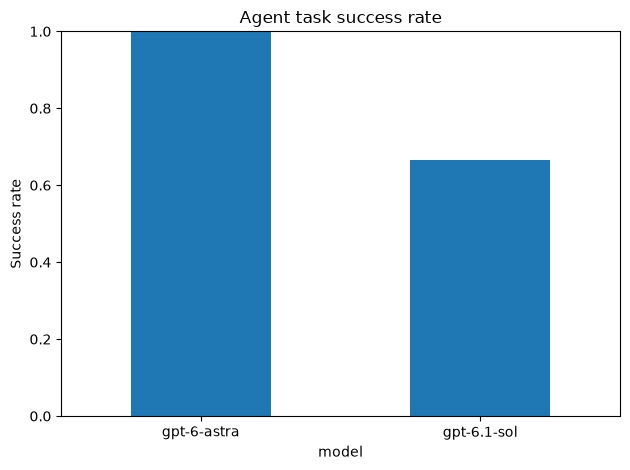

In [ ]:

if benchmark_df.empty:
    raise ValueError("No benchmark results were recorded.")

summary = (
    benchmark_df.groupby("model")
    .agg(
        tasks=("task_id", "count"),
        successful_tasks=("success", "sum"),
        mean_latency_seconds=("latency_seconds", "mean"),
        mean_tool_rounds=("tool_rounds", "mean"),
        total_input_tokens=("input_tokens", "sum"),
        total_output_tokens=("output_tokens", "sum"),
        total_estimated_cost_usd=("estimated_cost_usd", "sum"),
        total_tool_errors=("tool_errors", "sum"),
    )
    .reset_index()
)

summary["success_rate"] = (
    summary["successful_tasks"] / summary["tasks"]
)

display(summary)

summary.to_csv(
    RESULTS_DIR / "model_summary.csv",
    index=False,
)

ax = summary.plot(
    x="model",
    y="success_rate",
    kind="bar",
    legend=False,
    title="Agent task success rate",
    ylabel="Success rate",
    ylim=(0, 1),
    rot=0,
)
ax.figure.tight_layout()


In [ ]:

if all_trajectories:
    display(pd.DataFrame(all_trajectories))
else:
    print("No tool calls were recorded.")


,model,task_id,tool,arguments,result,valid
0,gpt-6-astra,T01,search_products,"{'query': 'moisturiser for sensitive skin', 's...","{'total_matches': 1, 'products': [{'sku': 'S00...",True
1,gpt-6-astra,T02,check_stock,{'sku': 'S003'},"{'sku': 'S003', 'name': 'Daily Hydration Gel',...",True
2,gpt-6-astra,T03,compare_products,"{'skus': ['S001', 'S002']}","{'comparison': [{'sku': 'S001', 'name': 'Niaci...",True
3,gpt-6.1-sol,T01,search_products,"{'query': 'moisturiser for sensitive skin', 's...","{'total_matches': 1, 'products': [{'sku': 'S00...",True
4,gpt-6.1-sol,T02,check_stock,{'sku': 'S003'},"{'sku': 'S003', 'name': 'Daily Hydration Gel',...",True
5,gpt-6.1-sol,T03,compare_products,"{'skus': ['S001', 'S002']}","{'comparison': [{'sku': 'S001', 'name': 'Niaci...",True


In [ ]:

import shutil
from IPython.display import display

archive_path = shutil.make_archive(
    str(RESULTS_DIR.resolve()),
    "zip",
    root_dir=str(RESULTS_DIR.resolve()),
)

print("Created:", archive_path)

try:
    from google.colab import files
    files.download(archive_path)
except ImportError:
    print("Not running in Colab. Retrieve the ZIP from the results directory.")


Created: /content/agentic_retail_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>